In [2]:
%pip install --force-reinstall mediapipe==0.10.14 opencv-python numpy pandas

4665.94s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


  Using cached mediapipe-0.10.14-cp312-cp312-macosx_11_0_universal2.whl.metadata (9.7 kB)
  Using cached opencv_python-5.0.0.93-cp37-abi3-macosx_13_0_arm64.whl.metadata (19 kB)
  Using cached numpy-2.5.4-cp312-cp312-macosx_14_0_arm64.whl.metadata (6.6 kB)
  Using cached pandas-3.0.6-cp312-cp312-macosx_11_0_arm64.whl.metadata (79 kB)
  Using cached absl_py-2.5.1-py3-none-any.whl.metadata (3.3 kB)
  Using cached attrs-26.1.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached jax-0.11.2-py3-none-any.whl.metadata (13 kB)
  Using cached jaxlib-0.11.2-cp312-cp312-macosx_11_0_arm64.whl.metadata (1.3 kB)
  Using cached matplotlib-3.11.2-cp312-cp312-macosx_11_0_arm64.whl.metadata (80 kB)
  Using cached opencv_contrib_python-5.0.0.93-cp37-abi3-macosx_13_0_arm64.whl.metadata (19 kB)
  Using cached protobuf-4.25.9-cp37-abi3-macosx_10_9_universal2.whl.metadata (541 bytes)
  Using cached sounddevice-0.5.6-py3-none-macosx_10_6_

In [6]:
%pip install seaborn

W0000 00:00:1792344560.142429 2091319 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792344560.155956 2091316 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792344560.185242 2091331 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792344560.212641 2091343 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792344560.218660 2091340 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792344560.239121 2091346 inference_feedback_manager.cc:114] Feedback manager 

Note: you may need to restart the kernel to use updated packages.


In [3]:
pip install pandas numpy matplotlib seaborn scikit-learn tabulate


4922.32s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


Note: you may need to restart the kernel to use updated packages.


# Can ML Fix My Tango Posture? A First Step Toward a Dance Assistant for Real-World Conditions

## 1. High-Level Explanation & Problem Definition

While I am definitely nowhere close to being a natural dancer, moving to Argentina as part of my Minerva rotation inspired me to embark on the journey of learning Argentine Tango. As someone who already struggles with postural issues due to scoliosis and constantly working like a "shrimp" at my computer, tango classes quickly taught me that maintaining a precise vertical center axis (*"el eje"*) and a stable embrace frame are essential for fluid improvisation. Dancers frequently struggle with unnoticed postural degradation, such as lower-back hyper-extension (**back-arching**) and upper-thoracic collapse (**slouching**). My tango instructor constantly emphasizes how these technical faults break partner connection, disrupt balance, and increase long-term injury risks.

In this project series, I aim to build a machine learning dance assistant that can eventually isolate the follower(me) from the leader and detect back-arching and slouching errors during real partner dancing. Building this system is surprisingly tricky due to real-world visual noise. Standard computer vision models that look directly at raw image pixels fail when simple environmental details change, such as switching between a bulky knit sweater and tight athletic clothes, moving between bright and dim lighting, or changing dance partners. As a first step toward addressing these challenges, this foundational baseline pipeline extracts 2D skeletal body joints from raw video frames using **MediaPipe Pose** and transforms them into a **scale-invariant hip–spine angle**, so the model focuses purely on body alignment rather than appearance. This lets me evaluate baseline structural faults and test how well simple classifiers (Logistic Regression, Naive Bayes, and Random Forest) generalize from one instructor to another. Isolating the follower from the leader and testing robustness across outfits and lighting are left for the next two pipelines.

This choice of feature reflects a fundamental principle in data modeling: measures are never neutral, and the feature representation we choose dictates what a model can learn. Raw screen coordinates or pixel values would be distorted by how far the dancer stands from the camera, their body size, and what they are wearing. Projecting each frame into a single geometric angle removes those effects, but it also has clear limits. Because the angle only measures how far the spine bends away from vertical, not in which direction, back-arching and slouching can produce overlapping angle values. The 2D angle also still depends on camera viewpoint, and in partner dancing the leader can block parts of the follower's body. Separating these overlapping profiles and handling partner occlusion are the focus of upcoming iterations.

## 2.Pipeline Diagram

![Pipeline diagram](figures/tango_pipeline_diagram.png)




## 3. Data Ingestion, Data Audit, and Preprocessing

My dataset consists of 2,022 frame samples extracted from eight video recordings (.MOV) of my live tango sessions with two different dance partners (Instructor A and Instructor B). To test how apparel impacts detection, I intentionally wore different outfits across the clips: a heavy, loose knit sweater, casual daywear, and tight athletic clothes. I ingested the raw video frame-by-frame using OpenCV (`cv2.VideoCapture`), sampling every 5th frame to reduce redundant video frames while keeping a diverse set of posture positions. I then passed each frame through MediaPipe Pose to convert raw video pixels into 2D skeletal body joint coordinates.

### 4.Programmatic Audit of Data Anomalies

Auditing my extracted dataset revealed three major real-world tracking issues that threatened my model's accuracy: partner occlusions (my instructor blocking the camera), rotational perspective changes as we turned, and 2D coordinate compression.

The loose knit sweater caused the most severe tracking errors. When running an uncleaned data test, the bulky fabric hid my actual body contours and threw off MediaPipe’s landmark positions. This caused the model to calculate "straight" posture angles (~168° to 179°) even during obvious moments where I was arching my back. When evaluating this under strict, leakage-free `GroupKFold` cross-validation (grouped by video file), this tracking error created a major blindspot—causing my models to completely fail when tested on the sweater video.

While my baseline pipeline handles these anomalies post-extraction by filtering out invalid joint angles in Pandas, this is only a temporary fix. I wasn't able to build a real-time visual filter to separate fabric movement from bone movement directly on the video stream yet. I plan to develop a more robust skeletal mesh filter in upcoming project iterations to dynamically handle apparel noise.

In [6]:
# Master Data Audit Display Block
import pandas as pd
df_audit = pd.read_csv("tango_posture_dataset.csv")


print("📊 VISUAL LANDMARK TRACKING ANOMALIES")


# Isolate the exact fabric inflation rows from your bulky sweater video
sweater_glitches = df_audit[(df_audit['video_source'] == 'instructorB_bad1.MOV') & (df_audit['hip_spine_angle'] > 162)].head(4)
print("\n📝 Sample of Apparel Silhouette Distortion Rows (instructorB_bad1.MOV):")
print(sweater_glitches[['video_source', 'clothing_type', 'hip_spine_angle', 'posture_label']].to_string(index=False))

# Isolate  joint collapses from your normal daywear video
axis_collapses = df_audit[(df_audit['video_source'] == 'instructorA_good1.MOV') & (df_audit['hip_spine_angle'] < 140)].head(2)
print("\n📝 Sample of Partner Occlusion Axis Collapse Rows (instructorA_good1.MOV):")
print(axis_collapses[['video_source', 'clothing_type', 'hip_spine_angle', 'posture_label']].to_string(index=False))


📊 VISUAL LANDMARK TRACKING ANOMALIES

📝 Sample of Apparel Silhouette Distortion Rows (instructorB_bad1.MOV):
        video_source   clothing_type  hip_spine_angle  posture_label
instructorB_bad1.MOV regular_sweater       166.571806              1
instructorB_bad1.MOV regular_sweater       165.024530              1
instructorB_bad1.MOV regular_sweater       167.017967              1
instructorB_bad1.MOV regular_sweater       166.471866              1

📝 Sample of Partner Occlusion Axis Collapse Rows (instructorA_good1.MOV):
         video_source  clothing_type  hip_spine_angle  posture_label
instructorA_good1.MOV normal_clothes        137.69712              0
instructorA_good1.MOV normal_clothes        132.01344              0


### 5.Math Behind the Model Selections


#### A. Gaussian Naive Bayes 
Naive Bayes asks: given this hip angle, which posture is most likely? For each posture $k$, it assumes the angle follows a bell curve (a Gaussian) with its own mean $\mu_k$ and variance $\sigma_k^2$. Both are estimated from the training frames of that posture:

$$P(X = x \mid Y = k) = \frac{1}{\sqrt{2\pi\sigma_k^2}} \exp\left(-\frac{(x - \mu_k)^2}{2\sigma_k^2}\right)$$

Bayes' rule then turns this into the probability of each posture given the angle:

$$P(Y = k \mid X = x) = \frac{P(Y = k) \cdot P(X = x \mid Y = k)}{\sum_{j} P(Y = j) \cdot P(X = x \mid Y = j)}$$

The model predicts the posture with the highest probability. With only one feature, the "naive" independence assumption has no effect.

#### B. Logistic Regression 
Logistic regression turns the hip angle into a probability that the frame is Arching ($y = 1$) rather than Good ($y = 0$). It takes a weighted version of the angle, $\beta_0 + \beta_1 x$, and passes it through the sigmoid function so the result is between 0 and 1:

$$P(Y = 1 \mid X = x) = \sigma(\beta_0 + \beta_1 x) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x)}}$$

The weights $\beta_0$ and $\beta_1$ set where the cutoff between the two postures sits and how sharp it is. They are found by minimizing the binary cross-entropy loss over the $m$ training frames, where $\hat{p}^{(i)}$ is the model's predicted probability for frame $i$:

$$\mathcal{L}(\beta) = -\frac{1}{m} \sum_{i=1}^{m} \left[ y^{(i)} \log \hat{p}^{(i)} + (1 - y^{(i)}) \log(1 - \hat{p}^{(i)}) \right]$$

For the three-class condition (Good, Arching, Slouching), scikit-learn uses the same idea with one score per class, turned into probabilities with the softmax function.


#### C. My own addition: Hip-Spine Angle Feature 
The models use one number per video frame: the angle at my left hip between my shoulder and my knee. MediaPipe gives the 2D position of each joint as a fraction of the image width and height. Call the shoulder $A(x_a, y_a)$, the hip $B(x_b, y_b)$ and the knee $C(x_c, y_c)$.

First, I make two vectors that start at the hip, one pointing to the shoulder and one to the knee:

$$\vec{u} = \begin{bmatrix} x_a - x_b \\ y_a - y_b \end{bmatrix}, \quad \vec{v} = \begin{bmatrix} x_c - x_b \\ y_c - y_b \end{bmatrix}$$

The angle between them comes from the dot product:

$$\theta = \arccos \left( \frac{\vec{u} \cdot \vec{v}}{\Vert\vec{u}\Vert_2 \, \Vert\vec{v}\Vert_2} \right)$$

In the code I compute the same angle with `arctan2`, which gives a value between 0° and 180°.

Subtracting the hip position removes where I am standing in the frame. Dividing by the vector lengths means the angle stays the same if I am closer to or farther from the camera. If every coordinate is multiplied by the same factor $k$, the factor cancels:

$$\frac{(k\vec{u}) \cdot (k\vec{v})}{\Vert k\vec{u} \Vert_2 \, \Vert k\vec{v} \Vert_2} = \frac{k^2 (\vec{u} \cdot \vec{v})}{k^2 \, \Vert \vec{u} \Vert_2 \, \Vert \vec{v} \Vert_2} = \frac{\vec{u} \cdot \vec{v}}{\Vert\vec{u}\Vert_2 \, \Vert\vec{v}\Vert_2}$$

This feature has limits. The angle is always positive, so it does not say which way I bend. Arching and slouching can give similar values. It also uses only my left side, and clothing can still change where MediaPipe places the joints, so it does not remove the clothing effect.



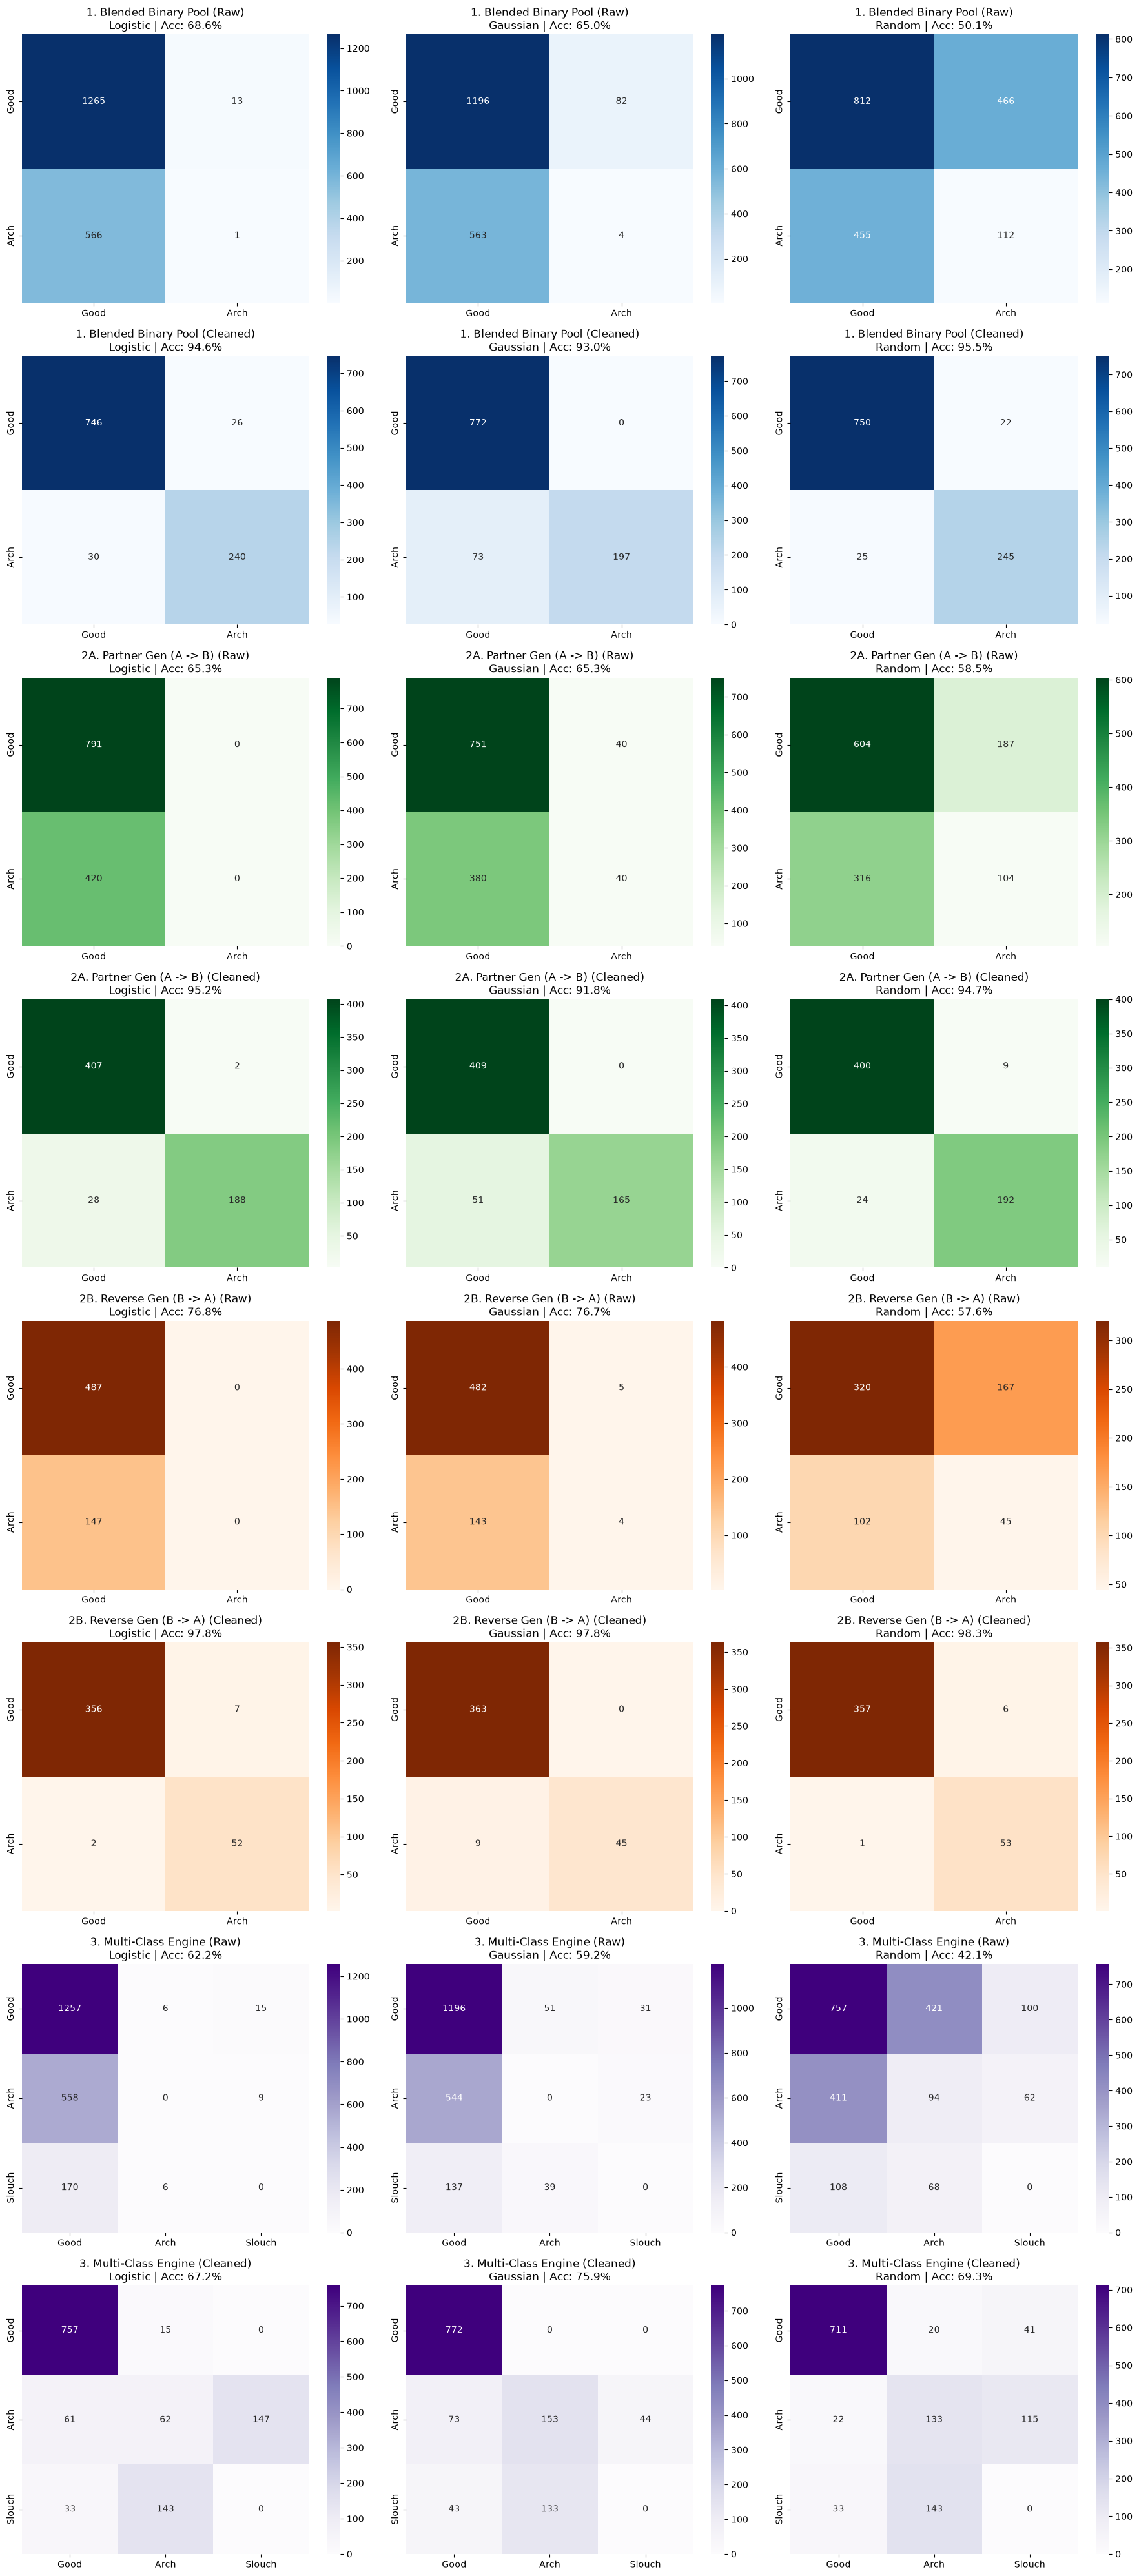

🚀Consolidated all 24 structural configurations into 'tango_factorial_matrices_v4.png'!


In [1]:
## 6. Main Body of Code for the Tango Posture Dataset Analysis and Visualization

#final final version 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupKFold, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score


# 1. LOADING DATASET AND COMPLITING EXPERIMENTAL POOLS

df_master = pd.read_csv("tango_posture_dataset.csv")

# Cleanning tracking anomalies based on my data audit constraints explained in sectio 4
good_clean = df_master[(df_master['posture_label'] == 0) & (df_master['hip_spine_angle'] >= 160)].copy()
arch_clean = df_master[(df_master['posture_label'] == 1) & (df_master['hip_spine_angle'] <= 162)].copy()
slouch_clean = df_master[(df_master['posture_label'] == 2)].copy()
df_cleaned_master = pd.concat([good_clean, arch_clean, slouch_clean], ignore_index=True)

# Define our 3 baseline and extension model variants
algorithms = {
    "Logistic Regression (Session 6)": LogisticRegression(max_iter=1000),
    "Gaussian Naive Bayes (Session 5)": GaussianNB(),
    "Random Forest (Extension Method)": RandomForestClassifier(n_estimators=100, random_state=42)
}

# Set up an expansive 8 rows by 3 columns symmetrical figure map panel
fig, axes = plt.subplots(8, 3, figsize=(18, 40))

# Tracking index dictionary to route subplots cleanly
row_map = {
    ("1. Blended Binary Pool (Raw)", False): 0,
    ("1. Blended Binary Pool (Cleaned)", True): 1,
    ("2A. Partner Gen (A -> B) (Raw)", False): 2,
    ("2A. Partner Gen (A -> B) (Cleaned)", True): 3,
    ("2B. Reverse Gen (B -> A) (Raw)", False): 4,
    ("2B. Reverse Gen (B -> A) (Cleaned)", True): 5,
    ("3. Multi-Class Engine (Raw)", False): 6,
    ("3. Multi-Class Engine (Cleaned)", True): 7
}


# 2. CORE FACTORIAL PLOTTING ENGINE

def render_factorial_row(df_pool, condition_name, is_cleaned):
    r_idx = row_map[(condition_name, is_cleaned)]
    cmap_color = "Purples" if "Multi-Class" in condition_name else ("Oranges" if "Reverse" in condition_name else ("Greens" if "Partner Gen" in condition_name else "Blues"))
    
    # Process Binary Conditions (1, 2A, 2B) vs Multi-Class Condition (3)
    if "Multi-Class" in condition_name:
        df_active = df_pool.copy()
        is_multi = True
    else:
        df_active = df_pool[df_pool['posture_label'].isin([0, 1])].copy()
        is_multi = False
        
    X = df_active[['hip_spine_angle']]
    y = df_active['posture_label']
    
    # Execute split mechanics depending on condition type (Cross-Validation vs Fixed Split)
    if "GroupKFold" in condition_name or "Engine" in condition_name or "Blended" in condition_name:
        # Cross-Validation Data Split Pathway
        groups = df_active['video_source']
        gkf = GroupKFold(n_splits=len(groups.unique()))
        
        for m_idx, (m_name, model) in enumerate(algorithms.items()):
            all_true, all_pred = [], []
            for train_idx, test_idx in gkf.split(X, y, groups=groups):
                model.fit(X.iloc[train_idx], y.iloc[train_idx])
                all_true.extend(y.iloc[test_idx])
                all_pred.extend(model.predict(X.iloc[test_idx]))
                
            acc = accuracy_score(all_true, all_pred)
            cm = confusion_matrix(all_true, all_pred)
            labels = ['Good', 'Arch', 'Slouch'] if is_multi else ['Good', 'Arch']
            
            sns.heatmap(cm, annot=True, fmt='d', cmap=cmap_color, ax=axes[r_idx, m_idx], xticklabels=labels, yticklabels=labels)
            axes[r_idx, m_idx].set_title(f"{condition_name}\n{m_name.split()[0]} | Acc: {acc*100:.1f}%")
    else:
        # Fixed Symmetrical Cross-Instructor Split Pathway
        df_inst_a = df_active[df_active['video_source'].str.contains('instructorA')]
        df_inst_b = df_active[df_active['video_source'].str.contains('instructorB')]
        
        X_a, y_a = df_inst_a[['hip_spine_angle']], df_inst_a['posture_label']
        X_b, y_b = df_inst_b[['hip_spine_angle']], df_inst_b['posture_label']
        
        if "A -> B" in condition_name:
            X_tr, y_tr, X_te, y_te = X_a, y_a, X_b, y_b
        else:
            X_tr, y_tr, X_te, y_te = X_b, y_b, X_a, y_a
            
        for m_idx, (m_name, model) in enumerate(algorithms.items()):
            model.fit(X_tr, y_tr)
            preds = model.predict(X_te)
            acc = accuracy_score(y_te, preds)
            cm = confusion_matrix(y_te, preds)
            
            sns.heatmap(cm, annot=True, fmt='d', cmap=cmap_color, ax=axes[r_idx, m_idx], xticklabels=['Good', 'Arch'], yticklabels=['Good', 'Arch'])
            axes[r_idx, m_idx].set_title(f"{condition_name}\n{m_name.split()[0]} | Acc: {acc*100:.1f}%")

# Execute row generation across the entire experimental factorial matrix grid
render_factorial_row(df_master, "1. Blended Binary Pool (Raw)", is_cleaned=False)
render_factorial_row(df_cleaned_master, "1. Blended Binary Pool (Cleaned)", is_cleaned=True)
render_factorial_row(df_master, "2A. Partner Gen (A -> B) (Raw)", is_cleaned=False)
render_factorial_row(df_cleaned_master, "2A. Partner Gen (A -> B) (Cleaned)", is_cleaned=True)
render_factorial_row(df_master, "2B. Reverse Gen (B -> A) (Raw)", is_cleaned=False)
render_factorial_row(df_cleaned_master, "2B. Reverse Gen (B -> A) (Cleaned)", is_cleaned=True)
render_factorial_row(df_master, "3. Multi-Class Engine (Raw)", is_cleaned=False)
render_factorial_row(df_cleaned_master, "3. Multi-Class Engine (Cleaned)", is_cleaned=True)

plt.tight_layout()
# Saved under a unique file name to keep my portfolio organized safely and avoid overwriting previous versions
plt.savefig("tango_factorial_matrices_v4.png", dpi=300)
plt.show()
print("🚀Consolidated all 24 structural configurations into 'tango_factorial_matrices_v4.png'!")



## 9. Overall Performance Discussion and Reflections

On the raw data, none of the three models did better than guessing. About 69% of the frames in the Good-vs-Arching data are Good, so predicting "Good" every time already scores about that. Logistic regression did almost exactly that: in the A-to-B test it labeled all 1,211 test frames as Good (`[[791, 0], [420, 0]]`, 65.3%), and in the leave-one-video-out test it found 1 of 567 Arching frames. Random Forest did predict Arching, but it also called many Good frames Arching, so its accuracy was lower (50.1% to 58.5%). My audit explains part of this. Loose sweater fabric and my partner blocking the camera moved the joint positions, so many Arching frames show a nearly straight angle and some Good frames show a very low one.

After I removed those frames, all three models did much better. On the cleaned data, accuracy was 93.0% to 95.5% with leave-one-video-out, 91.8% to 95.2% when training on Instructor A and testing on B, and 97.8% to 98.3% in the reverse direction. This suggests the angle carries over between the two instructors once the tracking errors are gone. Naive Bayes never called a Good frame Arching, but it missed more Arching frames (73 of 270 in the first test). There is an important caveat. The cleaning removed about 40% of the frames (2,021 down to 1,218), and my thresholds depend on the label (Good frames kept only above 160°, Arching frames only below 162°). That makes the problem easier for a model that uses only this angle. The cleaned numbers are therefore the best case, and the raw numbers are the more realistic ones.

The three-class results show the limits of one angle. Naive Bayes had the highest accuracy (75.9%), followed by Random Forest (69.3%) and logistic regression (67.2%), but that is mostly because Good frames are the largest class and are easy. No model labeled a slouching frame correctly. Naive Bayes predicted Arching for 133 of the 176 slouching frames, and logistic regression predicted Arching for 143. Logistic regression also labeled 147 of 270 Arching frames as Slouching. Two things likely cause this. First, the angle only measures how far the spine bends, not which way, so arching and slouching can look alike. Second, I have only one slouching video, so when it is held out for testing, the model never sees slouching during training. For that reason, I don't read the three-class result as proof that slouching can't be detected. In the next assignment I plan to record more slouching videos, add a feature that shows which direction I bend, and choose which frames to remove with a rule that doesn't use the labels.
 



## 9.Acknowledgements and AI Statements 


In this assignment I got the idea of using Jupyter Notebook instead of VS Code or Google Colab from Wen. He showed me a quick introduction to how to use Jupyter Notebook, since I have not used this before this assignment.I also Used Google search to see what the other methods of processing video are. Initially, I thought about taking screenshots, but then found the Media pose, which extracted frames in the video for me. 
I used different analysis we learned in class while did and extension of the class learning by using this. While I did the critical thinking, decision making and learning from trial and error such as trying to add a dummy variable, comparing the clean and raw data I benefit from gemini ai to help me with the coding.I also used claude ai built into my vs code to push my assignment into github which can be seen through my commits and have claude as a collobrator in my project. 

Consent: 
I have messaged both my instructors and explicity asked their consent while explaining clearly how their data will be used. Messages capturing their consent can be provided upon request. 


![Example frame from processing](figures/exampleimagefromprocessing.jpg)
